# 01 · Reproduce the SQL and Power BI numbers in Python

**Project 03: The Attrition Blindspot** (IBM HR Analytics, synthetic data)

**Purpose:** before any statistics or modelling, prove that Python reproduces the numbers already shown in
PostgreSQL (`sql/05_risk_score_validation.sql`) and in the Power BI dashboard. If three independent
implementations agree, every later result in this repository rests on a verified foundation.

**Inputs:** `data/processed/hr_attrition_clean.csv` (export of the SQL view `hr.employees_clean`)
**Logic:** `src/attrition/score.py` (the same points score as the SQL view and the DAX columns)

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from attrition.data import load_clean, repo_root
from attrition.score import WEIGHTS, add_score, band_summary, current_at_risk

pd.set_option("display.precision", 1)
df = load_clean()          # raises a clear error if the data does not match the SQL view
print(f"Loaded {len(df):,} employees x {df.shape[1]} columns; validation passed")
print(f"Leavers: {df['attrition_flag'].sum()} ({100 * df['attrition_flag'].mean():.1f}%)")

Loaded 1,470 employees x 39 columns; validation passed
Leavers: 237 (16.1%)


## 1. Risk score weights
Points are each driver's observed attrition lift, scaled to 100 (see `docs/data_dictionary.md`).

In [2]:
pd.Series(WEIGHTS, name="points").to_frame()

,points
overtime_flag,30
new_manager_flag,30
no_stock_options_flag,22
low_job_satisfaction_flag,12
below_level_median_pay_flag,6


## 2. Attrition by risk band (must match SQL Part B and dashboard Pages 1 and 3)

In [3]:
scored = add_score(df)
summary = band_summary(scored)
summary

,risk_band,headcount,leavers,attrition_pct
0,Low,516,25,4.8
1,Medium,606,78,12.9
2,High,223,70,31.4
3,Critical,125,64,51.2


In [4]:
expected = pd.DataFrame(
    {"risk_band": ["Low", "Medium", "High", "Critical"],
     "headcount": [516, 606, 223, 125],
     "leavers": [25, 78, 70, 64],
     "attrition_pct": [4.8, 12.9, 31.4, 51.2]}
)
check = summary.merge(expected, on="risk_band", suffixes=("_python", "_sql_dax"))
for col in ["headcount", "leavers", "attrition_pct"]:
    assert (check[f"{col}_python"] == check[f"{col}_sql_dax"]).all(), f"Mismatch in {col}"
print("Python matches SQL and Power BI for every band")

Python matches SQL and Power BI for every band


## 3. Current employees at High or Critical risk (must match dashboard Page 5)

In [5]:
at_risk = current_at_risk(scored)
page5 = pd.Series({
    "current staff at high or critical risk": len(at_risk),
    "of whom high performers": int((at_risk["high_performer_flag"] == 1).sum()),
    "working overtime": int((at_risk["overtime_flag"] == 1).sum()),
    "first year with a manager": int((at_risk["new_manager_flag"] == 1).sum()),
    "in the Critical band": int((at_risk["risk_band"] == "Critical").sum()),
}, name="count")
assert page5.tolist() == [214, 30, 139, 114, 61]
page5.to_frame()

,count
current staff at high or critical risk,214
of whom high performers,30
working overtime,139
first year with a manager,114
in the Critical band,61


## 4. Figure: attrition rises with the risk band

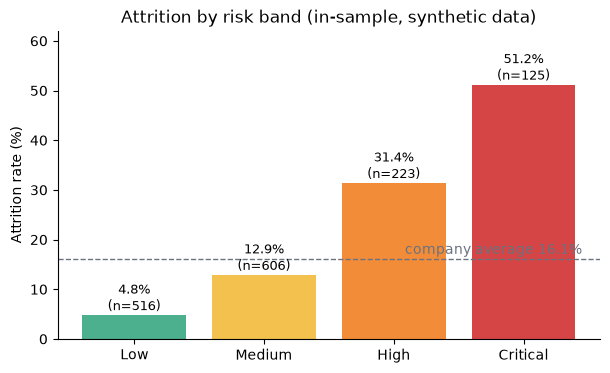

In [6]:
colours = {"Low": "#4CAF8E", "Medium": "#F2C14E", "High": "#F28C38", "Critical": "#D64545"}
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(summary["risk_band"].astype(str), summary["attrition_pct"],
              color=[colours[b] for b in summary["risk_band"].astype(str)])
ax.axhline(100 * df["attrition_flag"].mean(), color="#6B7280", linestyle="--", linewidth=1)
ax.text(3.45, 100 * df["attrition_flag"].mean() + 1, "company average 16.1%", ha="right", color="#6B7280")
for bar, pct, n in zip(bars, summary["attrition_pct"], summary["headcount"]):
    ax.text(bar.get_x() + bar.get_width() / 2, pct + 1, f"{pct}%\n(n={n})", ha="center", fontsize=9)
ax.set_ylabel("Attrition rate (%)")
ax.set_ylim(0, 62)
ax.set_title("Attrition by risk band (in-sample, synthetic data)")
ax.spines[["top", "right"]].set_visible(False)

out_dir = repo_root() / "reports" / "figures"
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "01_attrition_by_band.png", dpi=150, bbox_inches="tight")
plt.show()

## Result
Python, SQL and Power BI agree on every band and on all Page 5 counts, and the automated test suite
(`pytest`) re-checks this on every run. The bands are still **in-sample**: the weights were derived from the
same records, which is exactly what notebooks 03 and 04 test with held-out data.